In [1]:
import os
os.environ["XLA_PYTHON_CLIENT_PREALLOCATE"] = "false"
os.environ["XLA_PYTHON_CLIENT_MEM_FRACTION"] = "0.85"
os.environ["HF_ENDPOINT"] = "https://hf-mirror.com"
os.environ["HF_DATASETS_OFFLINE"] = "1"
os.environ["CUDA_VISIBLE_DEVICES"] = "0"

import dataclasses

import jax

from openpi.models import model as _model
from openpi.policies import droid_policy
from openpi.policies import policy_config as _policy_config
from openpi.shared import download
from openpi.training import config as _config
from openpi.training import data_loader as _data_loader

# Policy inference

The following example shows how to create a policy from a checkpoint and run inference on a dummy example.

In [2]:
config = _config.get_config("pi0_fast_droid")
checkpoint_dir = "/root/autodl-tmp/openpi/dir/pi0_fast_droid"

print("开始加载 policy...")
policy = _policy_config.create_trained_policy(config, checkpoint_dir)
print("policy 加载成功")

开始加载 policy...
policy 加载成功


In [3]:
import os
os.environ["HF_HUB_OFFLINE"] = "1"
os.environ["TRANSFORMERS_OFFLINE"] = "1"
os.environ["DATASETS_OFFLINE"] = "1"

from lerobot.common.datasets.lerobot_dataset import LeRobotDataset

dataset = LeRobotDataset(
    repo_id="droid_optimized",
    root="/root/autodl-tmp/openpi/droid_optimized",
    episodes=list(range(100)),
    # 不指定 video_backend，自动使用已修复的 torchcodec
)

print(dataset.features)

Resolving data files:   0%|          | 0/100 [00:00<?, ?it/s]

{'observation.images.exterior_image_1_left': {'dtype': 'video', 'shape': (180, 320, 3), 'names': ['height', 'width', 'channel'], 'video_info': {'video.fps': 15.0, 'video.codec': 'av1', 'video.pix_fmt': 'yuv420p', 'video.is_depth_map': False, 'has_audio': False}}, 'observation.images.exterior_image_2_left': {'dtype': 'video', 'shape': (180, 320, 3), 'names': ['height', 'width', 'channel'], 'video_info': {'video.fps': 15.0, 'video.codec': 'av1', 'video.pix_fmt': 'yuv420p', 'video.is_depth_map': False, 'has_audio': False}}, 'observation.images.wrist_image_left': {'dtype': 'video', 'shape': (180, 320, 3), 'names': ['height', 'width', 'channel'], 'video_info': {'video.fps': 15.0, 'video.codec': 'av1', 'video.pix_fmt': 'yuv420p', 'video.is_depth_map': False, 'has_audio': False}}, 'observation.state': {'dtype': 'float32', 'shape': (7,), 'names': {'motors': ['motor_0', 'motor_1', 'motor_2', 'motor_3', 'motor_4', 'motor_5', 'motor_6']}}, 'action': {'dtype': 'float32', 'shape': (7,), 'names': {'

In [4]:
import numpy as np
from openpi import transforms


class LeRobotToDroid(transforms.DataTransformFn):
    def __init__(
        self,
        model_state_dim: int = 8,
        gripper_dim: int = 1,
        default_gripper: float = 0.0,
    ):
        self.model_state_dim = model_state_dim
        self.gripper_dim = gripper_dim
        self.default_gripper = default_gripper

    def __call__(self, data: dict) -> dict:
        # 图像
        exterior = data["observation.images.exterior_image_1_left"]
        wrist = data["observation.images.wrist_image_left"]

        # state
        state = np.asarray(data["observation.state"], dtype=np.float32)
        if state.ndim == 0:
            state = state[np.newaxis]

        if state.shape[-1] < self.model_state_dim:
            pad_len = self.model_state_dim - state.shape[-1]
            # 只在最后一维补 gripper
            pad_width = [(0, 0)] * (state.ndim - 1) + [(0, pad_len)]
            state = np.pad(state, pad_width, constant_values=self.default_gripper)

        joint_dim = self.model_state_dim - self.gripper_dim
        joint = state[..., :joint_dim]
        gripper = state[..., joint_dim:]

        # prompt
        prompt = data["task"]

        return {
            "observation/exterior_image_1_left": exterior,
            "observation/wrist_image_left": wrist,
            "observation/joint_position": joint,
            "observation/gripper_position": gripper,
            "observation.state": state,
            "prompt": prompt,
        }


droid_inputs = LeRobotToDroid(model_state_dim=8, gripper_dim=1)

sample = dataset[100]
droid_obs = droid_inputs(sample)


# import numpy as np

# for k, v in droid_obs.items():
#     if k == "prompt":
#         print(k, repr(v)); continue
#     v = np.asarray(v)
#     print(f"{k:40s} shape={v.shape} dtype={v.dtype} min={v.min():.3f} max={v.max():.3f}")

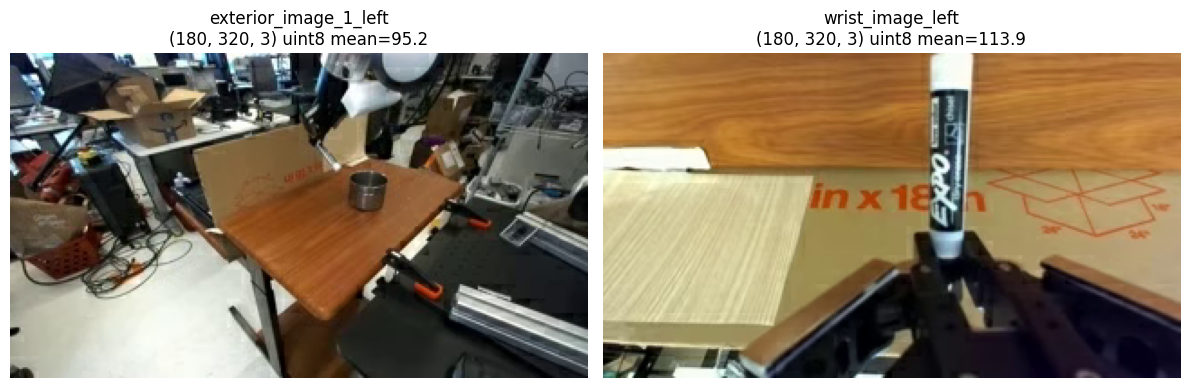

In [5]:
import numpy as np
import matplotlib.pyplot as plt

def to_hwc_uint8(img):
    img = np.asarray(img)                      # torch tensor 先 .cpu().numpy()
    if img.ndim == 3 and img.shape[0] == 3:
        img = np.transpose(img, (1, 2, 0))     # CHW -> HWC
    if img.dtype != np.uint8:
        img = (np.clip(img, 0, 1) * 255).round().astype(np.uint8)
    return img

keys = ["observation/exterior_image_1_left", "observation/wrist_image_left"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, k in zip(axes, keys):
    img = to_hwc_uint8(droid_obs[k])
    ax.imshow(img)
    ax.set_title(f"{k.split('/')[-1]}\n{img.shape} {img.dtype} mean={img.mean():.1f}")
    ax.axis("off")
plt.tight_layout()
plt.show()


In [6]:
# Run inference on a dummy example. This example corresponds to observations produced by the DROID runtime.
# example = droid_policy.make_droid_example()
# result = policy.infer(example)
result = policy.infer(droid_obs)

# Delete the policy to free up memory.
# del policy

print("Actions shape:", result["actions"].shape)

result

Actions shape: (10, 8)


{'actions': array([[-0.2646729 , -0.2416712 , -0.0748675 , -0.08204417,  0.24097269,
         -0.14176532, -0.10930717, -0.00596324],
        [-0.27689827, -0.23144727, -0.08745871, -0.13198167,  0.27717849,
         -0.10108574, -0.11819401, -0.00596324],
        [-0.29391077, -0.21200021, -0.10728268, -0.20233647,  0.32490964,
         -0.04237625, -0.13165767, -0.00596324],
        [-0.30394611, -0.18523362, -0.12572297, -0.25549917,  0.35203846,
          0.00533275, -0.14281397, -0.00596324],
        [-0.29592294, -0.1537676 , -0.13429861, -0.2719239 ,  0.34055008,
          0.02650194, -0.1450046 , -0.00596324],
        [-0.26438511, -0.12068228, -0.12804421, -0.26100814,  0.29674847,
          0.02739959, -0.13457502, -0.00596324],
        [-0.21241975, -0.08921627, -0.107572  , -0.2493338 ,  0.24376131,
          0.02727353, -0.11254613, -0.00596324],
        [-0.15135514, -0.06244968, -0.07901188, -0.25703125,  0.20374371,
          0.04052608, -0.0845144 , -0.00596324],
     

In [7]:
import numpy as np

import numpy as np

FPS = 15

def chunk_displacement(actions, mode="position", fps=15, state=None):
    """返回 (disp, net_disp)。disp: (N, D) 相对起点的累计位移;net_disp: (D,) 窗口净位移。"""
    a = np.asarray(actions, dtype=np.float64)
    if mode == "position":
        origin = a[0] if state is None else np.asarray(state, dtype=np.float64)
        disp = a - origin
    elif mode == "velocity":
        disp = np.cumsum(a / fps, axis=0)
    elif mode == "delta":
        disp = np.cumsum(a, axis=0)
    else:
        raise ValueError(f"unknown mode: {mode}")
    return disp, disp[-1]

def chunk_velocity(actions, fps=15, mode="position"):
    """返回 (vel, t_vel)。position 模式下 N 个点得到 N-1 个速度,时间取区间中点。"""
    a = np.asarray(actions, dtype=np.float64)
    dt = 1.0 / fps
    if mode == "position":
        vel = np.diff(a, axis=0) / dt
        t_vel = (np.arange(len(a) - 1) + 0.5) * dt
    elif mode == "velocity":
        vel = a
        t_vel = np.arange(len(a)) * dt
    elif mode == "delta":
        vel = a / dt
        t_vel = np.arange(len(a)) * dt
    else:
        raise ValueError(f"unknown mode: {mode}")
    return vel, t_vel

def chunk_acceleration(actions, fps=15, mode="position"):
    """返回 (acc, t_acc)。在速度上再做一次一阶差分,时间取相邻速度时刻的中点。"""
    dt = 1.0 / fps
    vel, t_vel = chunk_velocity(actions, fps=fps, mode=mode)
    acc = np.diff(vel, axis=0) / dt
    t_acc = (t_vel[:-1] + t_vel[1:]) / 2
    return acc, t_acc
    
# result = policy.infer(droid_obs)          # 或者你保存这个字典的那个变量
acts = np.asarray(result["actions"], dtype=np.float64)
print("ptp:", np.ptp(acts[:, :7], axis=0))   # 应该非零

disp, net = chunk_displacement(acts[:, :7], mode="position", fps=15)
print("net disp:", net)



ptp: [0.23839524 0.20889252 0.09891982 0.22171505 0.17300301 0.22592877
 0.10154726]
net disp: [ 0.19912203  0.20889252  0.03948871 -0.22171505 -0.06193723  0.22592877
  0.06584982]


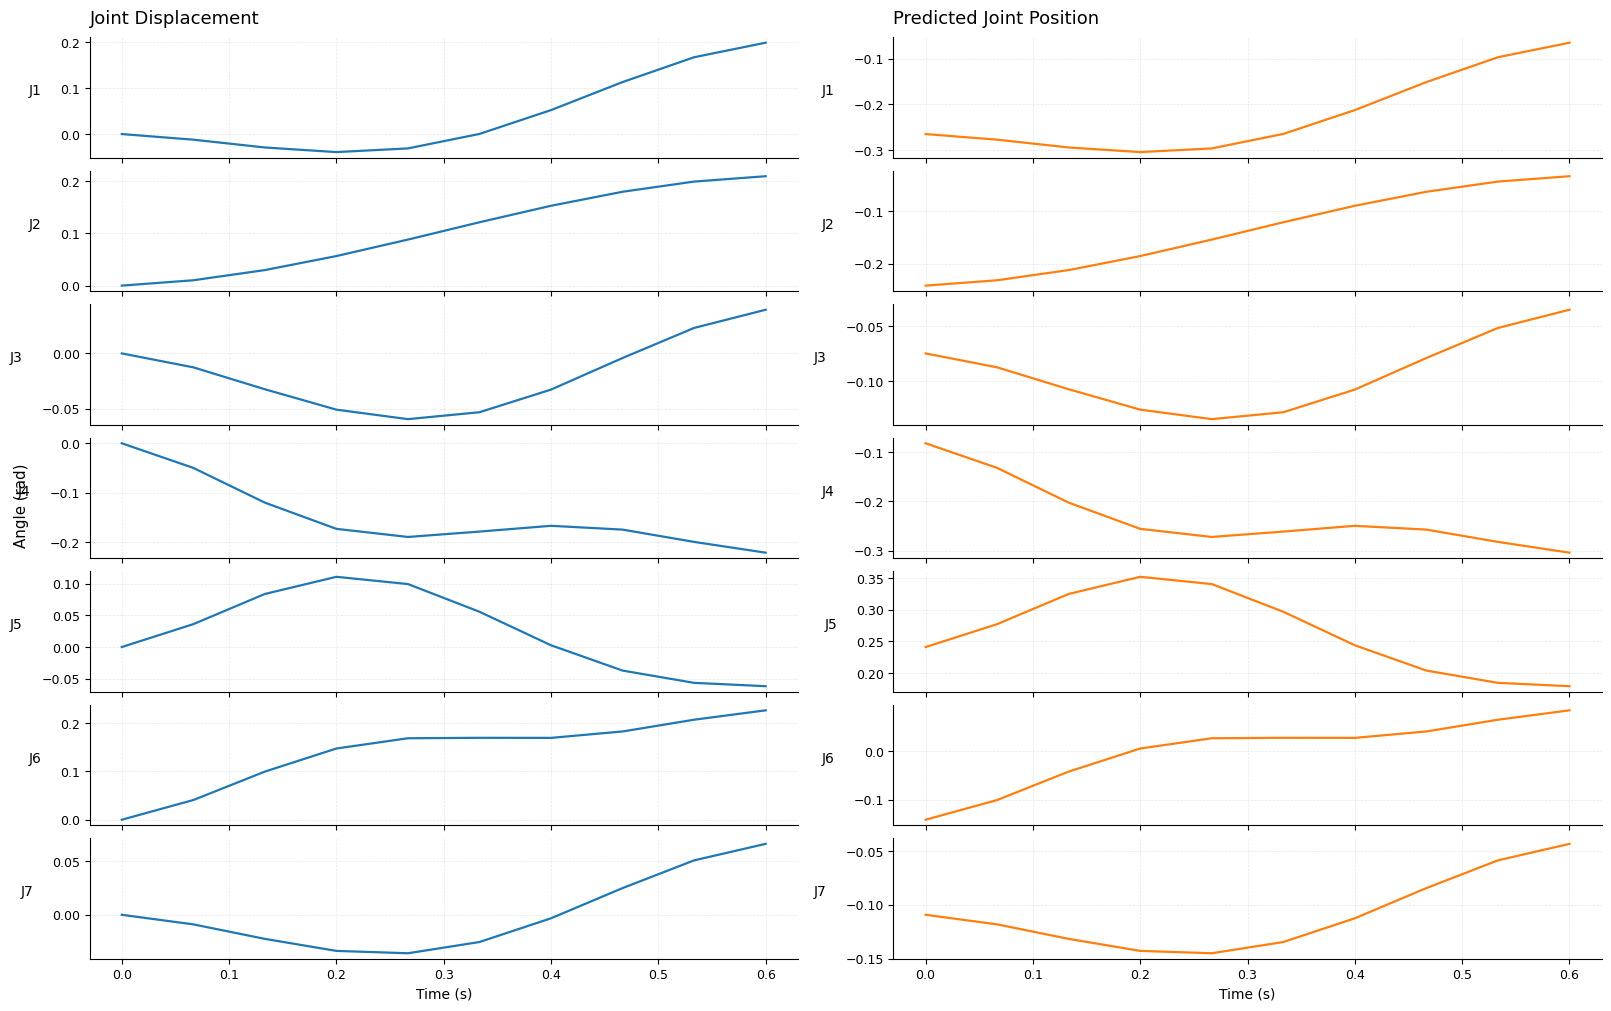

In [11]:
import numpy as np
import matplotlib.pyplot as plt

FPS = 15
acts = np.asarray(result["actions"], dtype=np.float64)[:, :7]
disp, net = chunk_displacement(acts, mode="position", fps=FPS)
t = np.arange(len(acts)) / FPS

plt.rcParams.update({
    "font.size": 9,
    "axes.titlesize": 13,
    "axes.labelsize": 10,
})

fig, axes = plt.subplots(
    7, 2,
    figsize=(16, 10),
    sharex="col",
    constrained_layout=True
)

for j in range(7):
    # 左列：相对起点的累计位移
    ax = axes[j, 0]
    ax.plot(t, disp[:, j], color="tab:blue", linewidth=1.6)
    ax.set_ylabel(f"J{j+1}", rotation=0, labelpad=18)
    ax.grid(True, linestyle="--", linewidth=0.5, alpha=0.3)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    # 右列：预测的原始关节位置
    ax = axes[j, 1]
    ax.plot(t, acts[:, j], color="tab:orange", linewidth=1.6)
    ax.set_ylabel(f"J{j+1}", rotation=0, labelpad=18)
    ax.grid(True, linestyle="--", linewidth=0.5, alpha=0.3)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

axes[0, 0].set_title("Joint Displacement", loc="left", pad=10)
axes[0, 1].set_title("Predicted Joint Position", loc="left", pad=10)

axes[-1, 0].set_xlabel("Time (s)")
axes[-1, 1].set_xlabel("Time (s)")

fig.supylabel("Angle (rad)", x=0.005)
fig.savefig("joint_tracking_comparison.png", dpi=200, bbox_inches="tight")
plt.show()

max |vel|: [0.916  0.4963 0.4284 1.0553 0.7948 0.8806 0.4205]


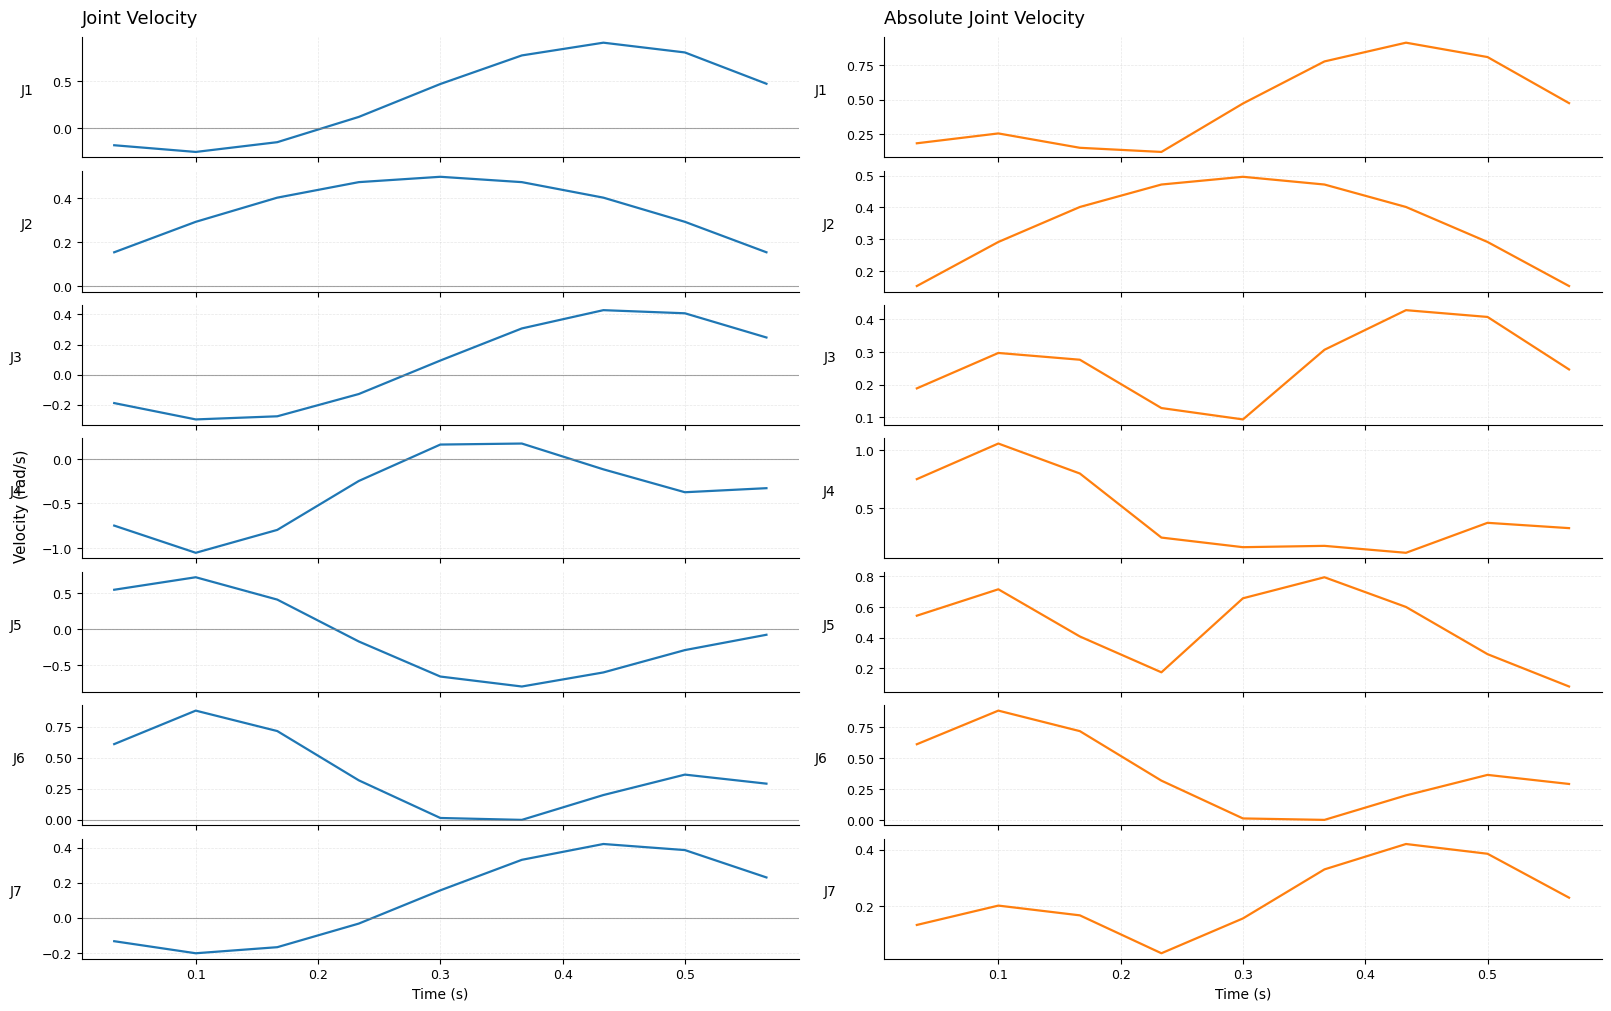

In [12]:
import numpy as np
import matplotlib.pyplot as plt

FPS = 15
vel, t_vel = chunk_velocity(acts, fps=FPS, mode="position")

np.set_printoptions(precision=4, suppress=True)
print("max |vel|:", np.abs(vel).max(axis=0))

fig, axes = plt.subplots(
    7, 2,
    figsize=(16, 10),
    sharex="col",
    constrained_layout=True
)

for j in range(vel.shape[1]):
    # 左列：带方向的关节速度
    ax = axes[j, 0]
    ax.plot(t_vel, vel[:, j], color="tab:blue", linewidth=1.6)
    ax.axhline(0, color="gray", linewidth=0.8, alpha=0.7)
    ax.set_ylabel(f"J{j+1}", rotation=0, labelpad=18)
    ax.grid(True, linestyle="--", linewidth=0.5, alpha=0.3)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    # 右列：关节速度绝对值
    ax = axes[j, 1]
    ax.plot(t_vel, np.abs(vel[:, j]), color="tab:orange", linewidth=1.6)
    ax.set_ylabel(f"J{j+1}", rotation=0, labelpad=18)
    ax.grid(True, linestyle="--", linewidth=0.5, alpha=0.3)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

axes[0, 0].set_title("Joint Velocity", loc="left", pad=10)
axes[0, 1].set_title("Absolute Joint Velocity", loc="left", pad=10)

axes[-1, 0].set_xlabel("Time (s)")
axes[-1, 1].set_xlabel("Time (s)")

fig.supylabel("Velocity (rad/s)", x=0.005)
fig.savefig("joint_velocity_comparison.png", dpi=200, bbox_inches="tight")
plt.show()

acc shape: (8, 7)
max |acc|: [5.291 2.075 3.337 8.266 8.689 5.971 2.84 ]


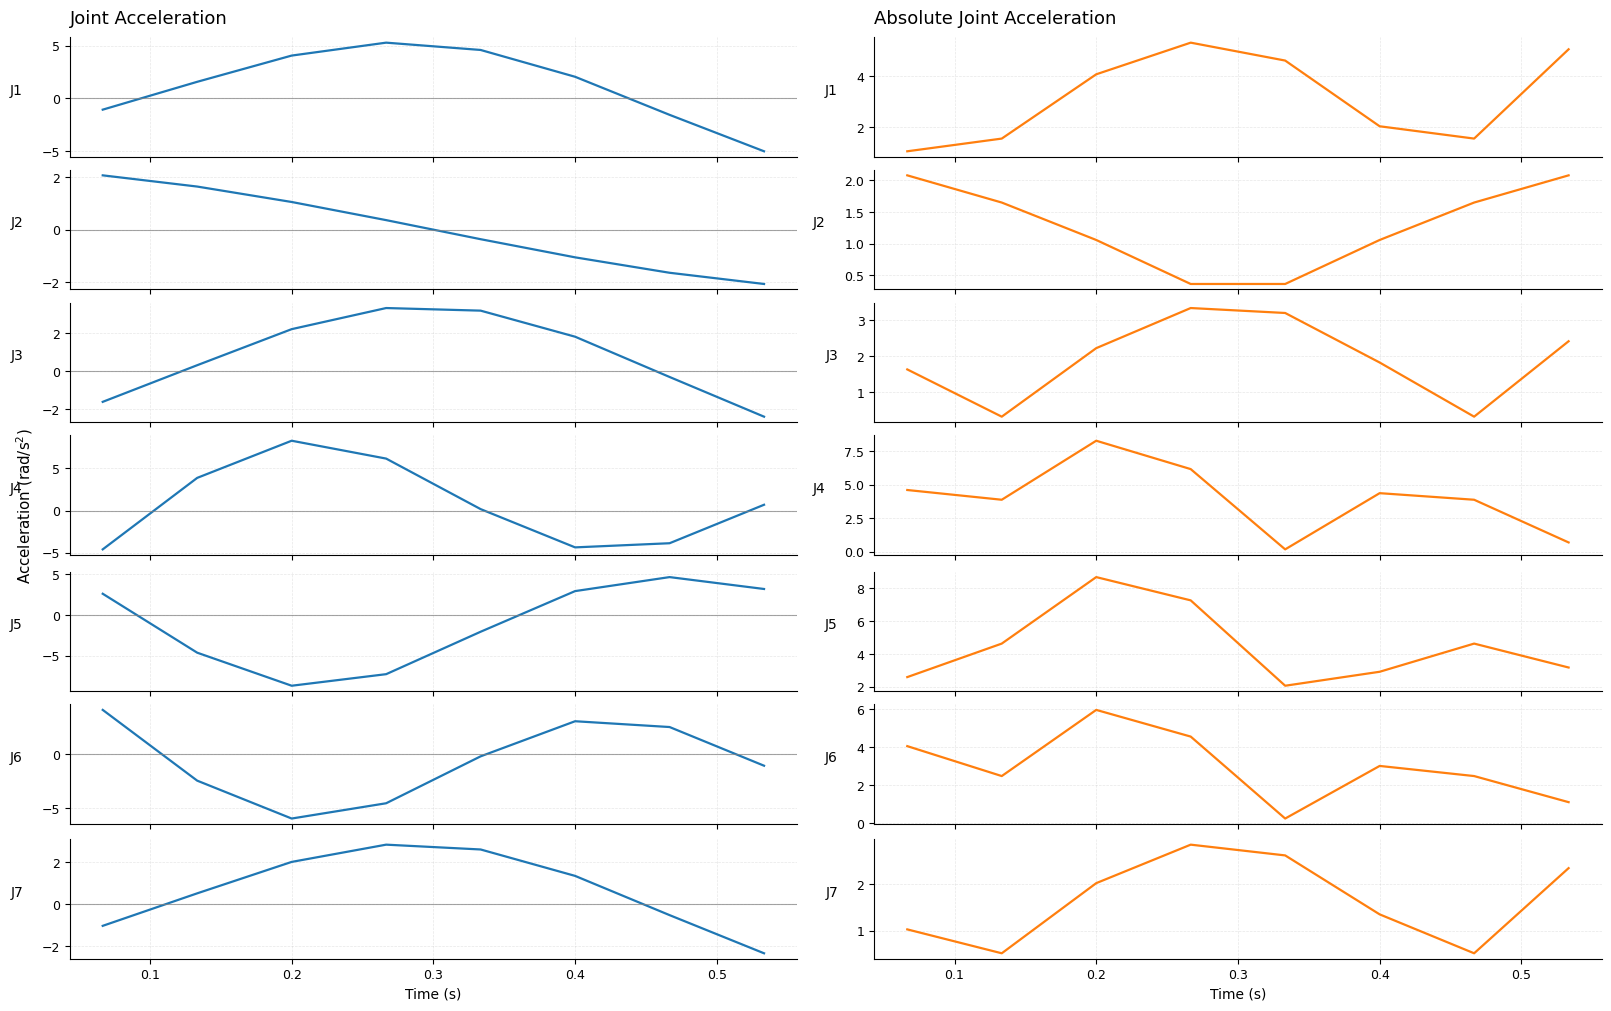

In [13]:
import numpy as np
import matplotlib.pyplot as plt

FPS = 15
acc, t_acc = chunk_acceleration(acts, fps=FPS, mode="position")

np.set_printoptions(precision=3, suppress=True)
print("acc shape:", acc.shape)
print("max |acc|:", np.abs(acc).max(axis=0))

fig, axes = plt.subplots(
    7, 2,
    figsize=(16, 10),
    sharex="col",
    constrained_layout=True
)

for j in range(acc.shape[1]):
    # 左列：带方向的关节加速度
    ax = axes[j, 0]
    ax.plot(t_acc, acc[:, j], color="tab:blue", linewidth=1.6)
    ax.axhline(0, color="gray", linewidth=0.8, alpha=0.7)
    ax.set_ylabel(f"J{j+1}", rotation=0, labelpad=18)
    ax.grid(True, linestyle="--", linewidth=0.5, alpha=0.3)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    # 右列：加速度绝对值
    ax = axes[j, 1]
    ax.plot(t_acc, np.abs(acc[:, j]), color="tab:orange", linewidth=1.6)
    ax.set_ylabel(f"J{j+1}", rotation=0, labelpad=18)
    ax.grid(True, linestyle="--", linewidth=0.5, alpha=0.3)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

axes[0, 0].set_title("Joint Acceleration", loc="left", pad=10)
axes[0, 1].set_title("Absolute Joint Acceleration", loc="left", pad=10)

axes[-1, 0].set_xlabel("Time (s)")
axes[-1, 1].set_xlabel("Time (s)")

fig.supylabel(r"Acceleration (rad/s$^2$)", x=0.005)
fig.savefig("joint_acceleration_comparison.png", dpi=200, bbox_inches="tight")
plt.show()

In [16]:
import numpy as np
import pandas as pd

FPS = 15

def stream_infer(policy, dataset, make_obs, start, end, stride=1):
    """对 [start, end) 每 stride 帧推理一次,返回 {t0: (H, 7)}。start/end 必须在同一个 episode 内。"""
    chunks = {}
    for t0 in range(start, end, stride):
        obs = make_obs(dataset[t0])            # 必须真正用到 t0
        chunks[t0] = np.asarray(policy.infer(obs)["actions"], dtype=np.float64)[:, :7]
    return chunks

def stitch(chunks, k):
    """拼接流:每个块只取前 k 步。stride 需等于 k。"""
    return np.concatenate([c[:k] for _, c in sorted(chunks.items())], axis=0)

def ensemble(chunks, T, m=0.1):
    """融合流:同一时间步的多个预测按指数权重平均,最旧的权重最大。"""
    H = next(iter(chunks.values())).shape[0]
    num, den = np.zeros((T, 7)), np.zeros((T, 1))
    for t0, c in chunks.items():
        for h in range(H):
            t = t0 - min(chunks) + h
            if t >= T:
                break
            w = np.exp(-m * (H - 1 - h))       # h 越大代表块越旧
            num[t] += w * c[h]
            den[t] += w
    return num / den

def smooth_kinematics(x, fps=FPS, alpha=0.3):
    """前后向 EWMA 平滑位置(避免单向滤波的相位滞后),再用中心差分求 v、a。"""
    dt = 1.0 / fps
    fwd = pd.DataFrame(x).ewm(alpha=alpha, adjust=False).mean().to_numpy()
    bwd = pd.DataFrame(x[::-1]).ewm(alpha=alpha, adjust=False).mean().to_numpy()[::-1]
    xs = (fwd + bwd) / 2
    v = np.gradient(xs, dt, axis=0)
    a = np.gradient(v, dt, axis=0)
    return xs, v, a


In [15]:
# 滑动窗口

import time
import numpy as np

FPS = 15
START, END, STRIDE = 10, 1000, 1   # 下标范围和步长。stride=1 约 990 次推理

records = []
chunks = {}   # idx -> (10, 7) 原始动作块,方便之后拼接或融合

t0 = time.time()
for idx in range(START, END, STRIDE):
    sample = dataset[idx]
    droid_obs = droid_inputs(sample)
    result = policy.infer(droid_obs)

    acts = np.asarray(result["actions"], dtype=np.float64)[:, :7]   # 只取前 7 维,去掉夹爪
    disp, net = chunk_displacement(acts, mode="position", fps=FPS)
    vel, t_vel = chunk_velocity(acts, fps=FPS, mode="position")
    acc, t_acc = chunk_acceleration(acts, fps=FPS, mode="position")

    chunks[idx] = acts
    records.append({
        "idx": idx,
        "episode": int(sample["episode_index"]) if "episode_index" in sample else -1,
        "state": np.asarray(sample["observation.state"], dtype=np.float64),
        "net_disp": net,
        "path_len": np.abs(np.diff(acts, axis=0)).sum(axis=0),
        "max_vel": np.abs(vel).max(axis=0),
        "max_acc": np.abs(acc).max(axis=0),
        "const": bool(np.ptp(acts, axis=0).max() == 0),
        "infer_ms": result["policy_timing"]["infer_ms"],
    })

# 汇总成数组,第一维是推理次数 M
idxs     = np.array([r["idx"] for r in records])
episodes = np.array([r["episode"] for r in records])
states   = np.stack([r["state"] for r in records])
net_disp = np.stack([r["net_disp"] for r in records])    # (M, 7)
path_len = np.stack([r["path_len"] for r in records])    # (M, 7)
max_vel  = np.stack([r["max_vel"] for r in records])     # (M, 7)
max_acc  = np.stack([r["max_acc"] for r in records])     # (M, 7)
is_const = np.array([r["const"] for r in records])
infer_ms = np.array([r["infer_ms"] for r in records])

# 检查
n_unique_state = len({s.tobytes() for s in states})
print(f"推理 {len(records)} 次,用时 {time.time() - t0:.0f}s,平均 infer {infer_ms.mean():.0f} ms")
print(f"涉及 episode: {np.unique(episodes)}")
print(f"不同的 state 数: {n_unique_state} / {len(records)}")
print(f"常量块数量: {is_const.sum()}")
if n_unique_state == 1:
    print("警告: 所有样本的 state 相同,droid_inputs 可能没有用到 sample")

np.set_printoptions(precision=3, suppress=True)
print("max|vel| 全程最大:", max_vel.max(axis=0))
print("max|acc| 全程最大:", max_acc.max(axis=0))


推理 990 次,用时 401s,平均 infer 361 ms
涉及 episode: [0 1 2 3 4 5]
不同的 state 数: 990 / 990
常量块数量: 188
max|vel| 全程最大: [ 8.365  8.183  8.557  9.693  9.625 10.304  6.277]
max|acc| 全程最大: [134.886 113.526 135.452 164.819 163.825 165.132  95.188]


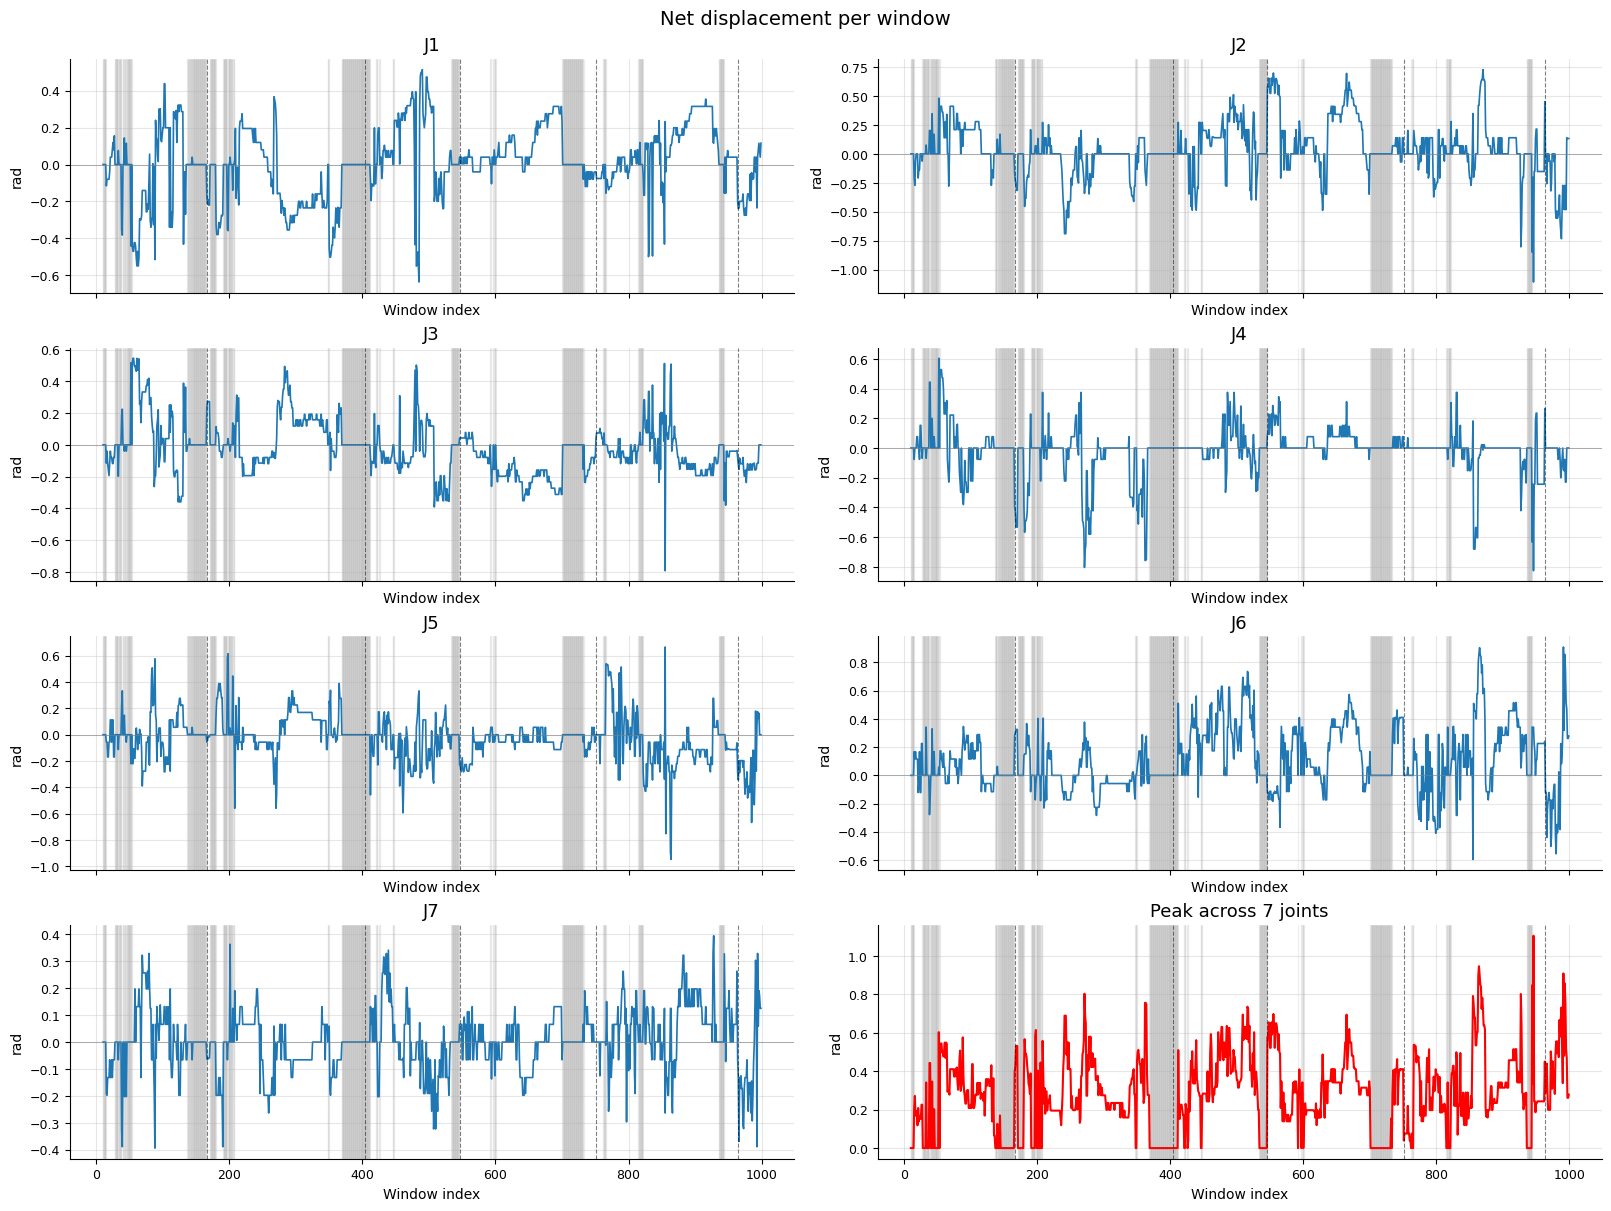

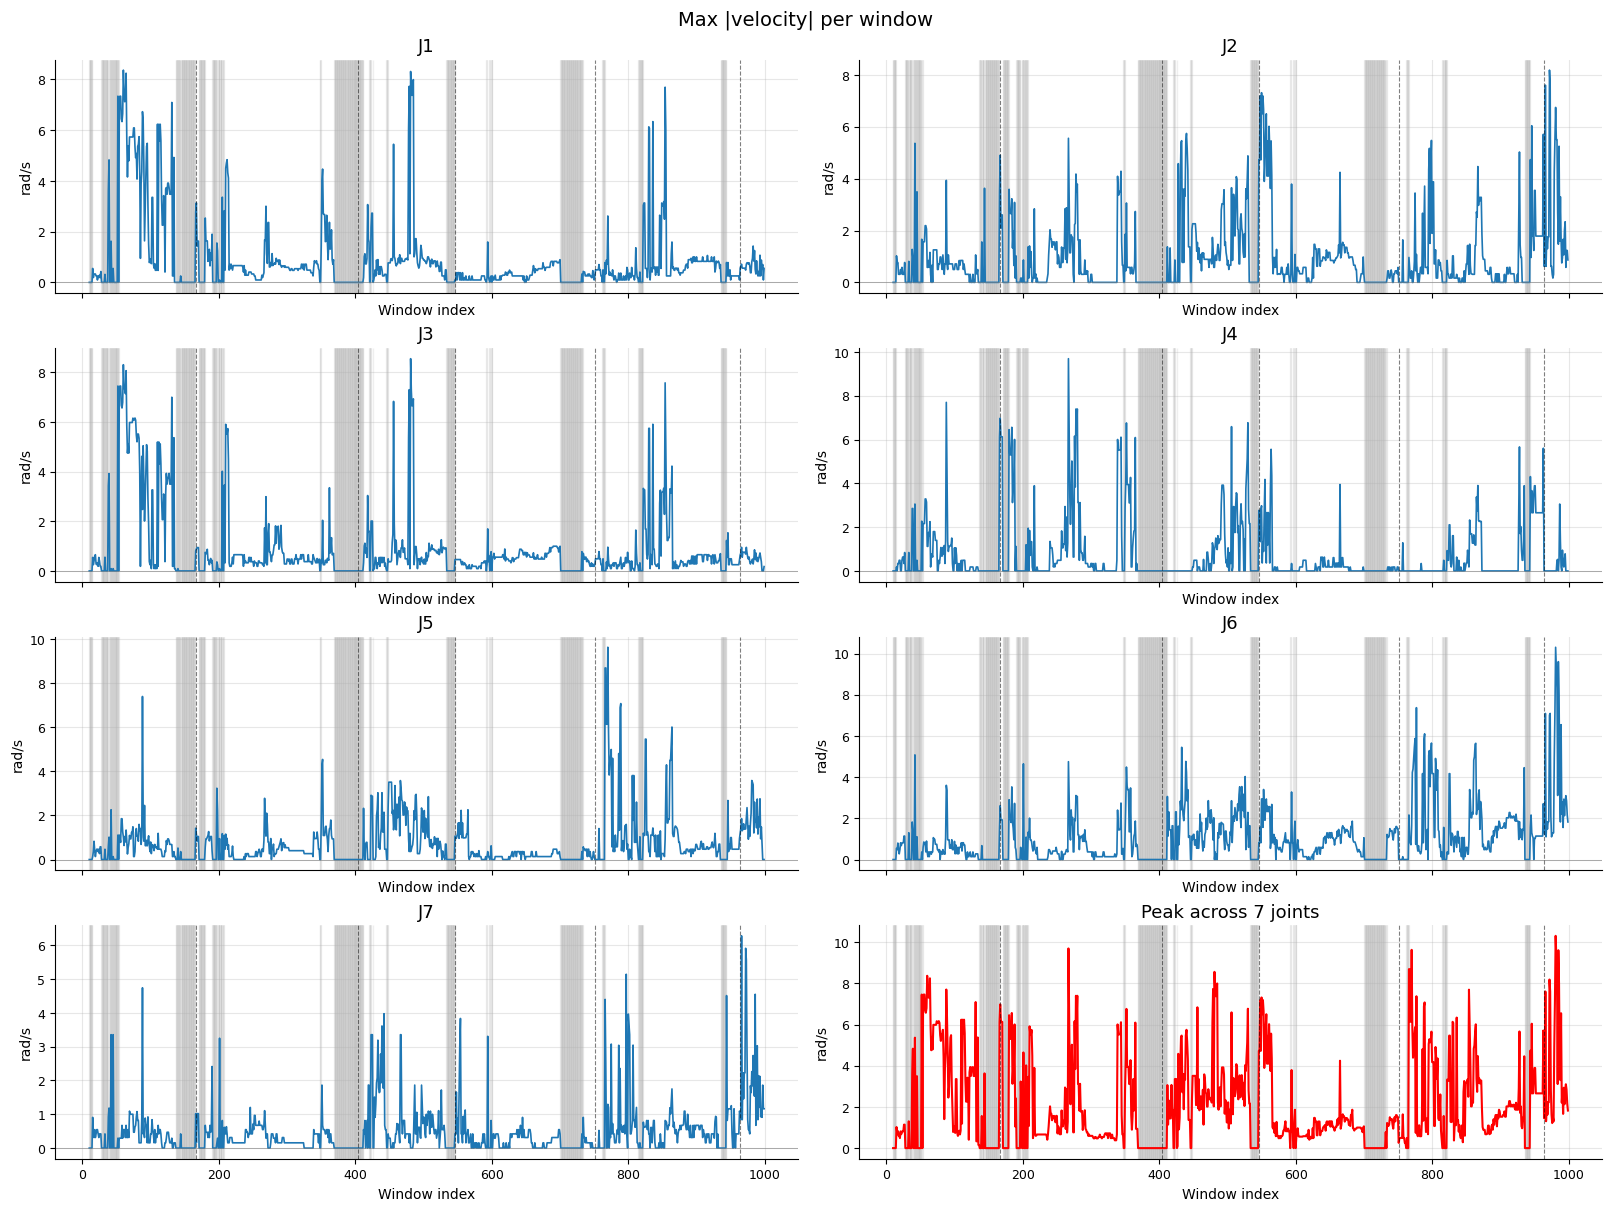

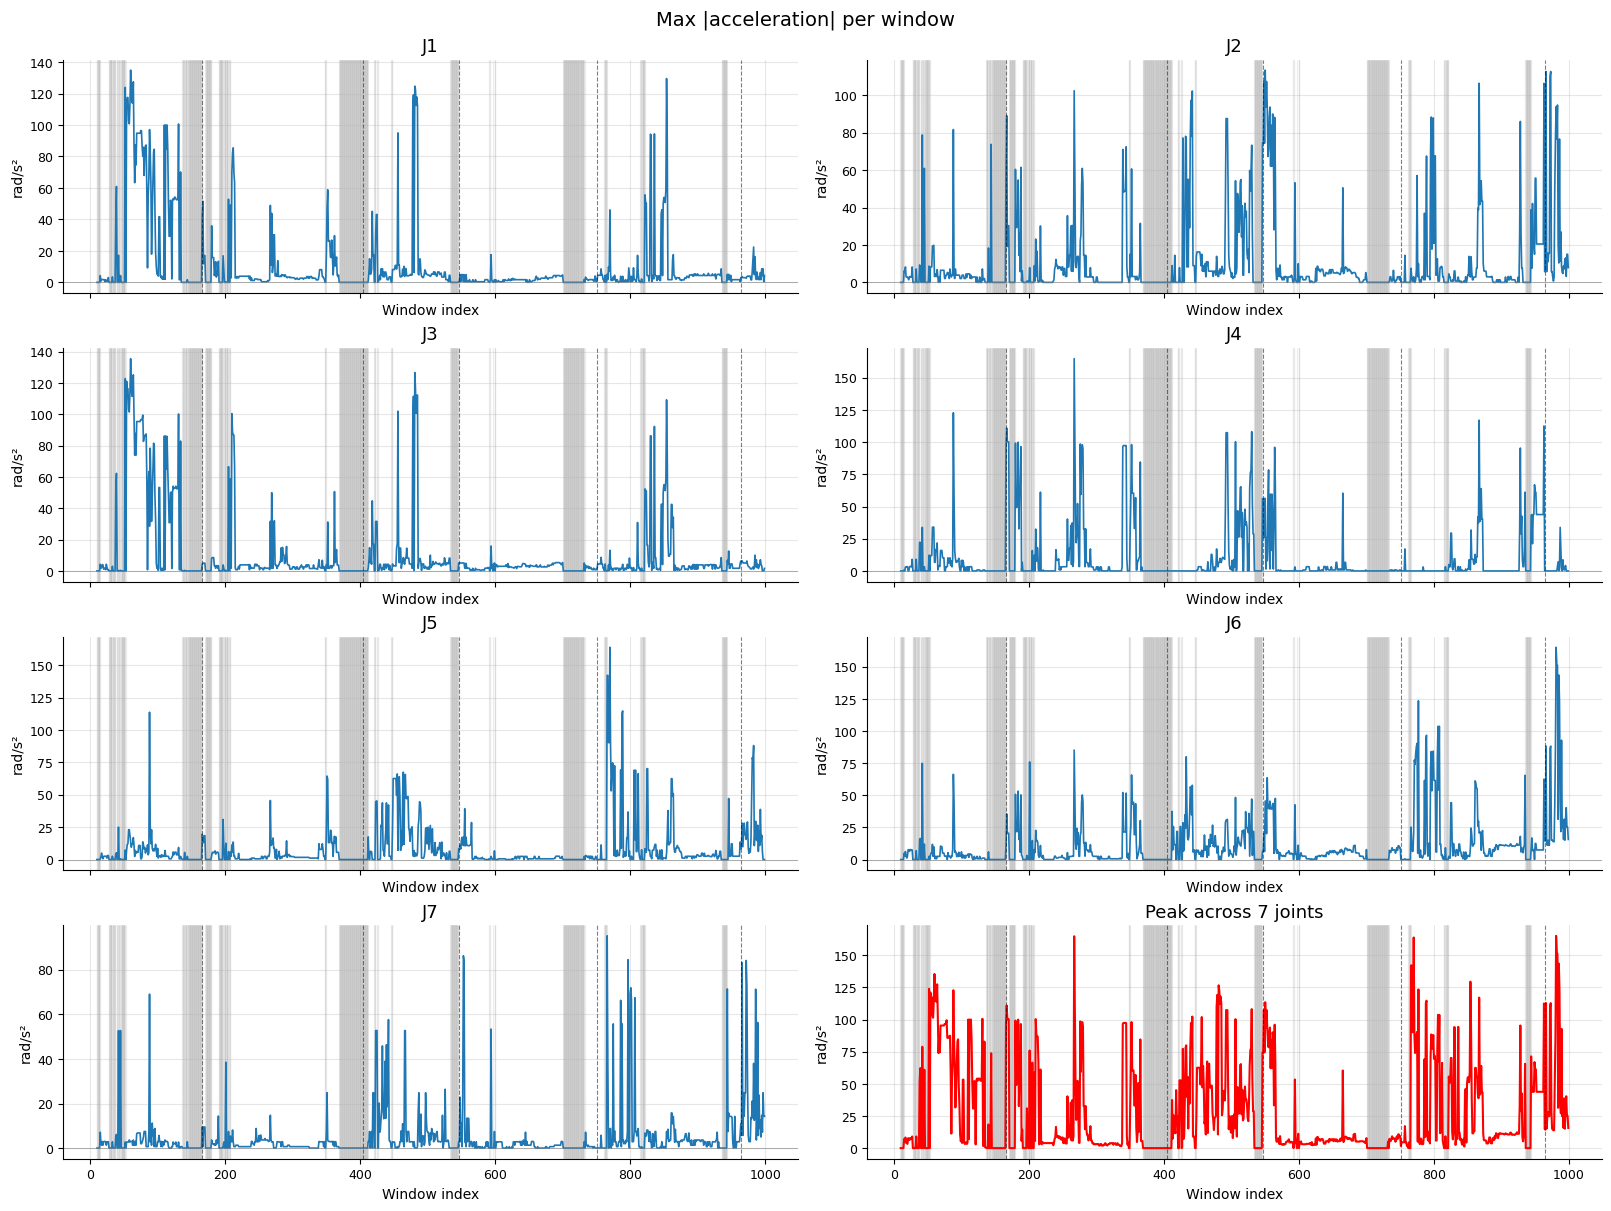

In [21]:
series = [
    (net_disp, "Net displacement per window", "rad",
     "net_displacement_per_window.png"),
    (max_vel, "Max |velocity| per window", "rad/s",
     "max_velocity_per_window.png"),
    (max_acc, "Max |acceleration| per window", "rad/s²",
     "max_acceleration_per_window.png"),
]

boundaries = idxs[1:][np.diff(episodes) != 0]

for data, title, unit, filename in series:
    fig, axes = plt.subplots(
        4, 2, figsize=(16, 12),
        sharex=True, constrained_layout=True
    )
    axes = axes.flatten()

    # 子图 1–7：七个关节分别绘制
    for j in range(data.shape[1]):
        ax = axes[j]
        ax.plot(idxs, data[:, j], linewidth=1.2)
        ax.set_title(f"J{j + 1}")
        ax.set_ylabel(unit)
        ax.grid(True, alpha=0.3)
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
        ax.axhline(0, color="gray", linewidth=0.7, alpha=0.6)

        for b in boundaries:
            ax.axvline(b, color="black", linestyle="--",
                       linewidth=0.8, alpha=0.5)

        for i in np.where(is_const)[0]:
            ax.axvspan(idxs[i] - 0.5, idxs[i] + 0.5,
                       color="gray", alpha=0.12)

    # 子图 8：七个关节的整体峰值
    ax = axes[7]
    overall = np.max(np.abs(data), axis=1)
    ax.plot(idxs, overall, color="red", linewidth=1.5)
    ax.set_title("Peak across 7 joints")
    ax.set_ylabel(unit)
    ax.grid(True, alpha=0.3)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    for b in boundaries:
        ax.axvline(b, color="black", linestyle="--",
                   linewidth=0.8, alpha=0.5)

    for i in np.where(is_const)[0]:
        ax.axvspan(idxs[i] - 0.5, idxs[i] + 0.5,
                   color="gray", alpha=0.12)

    for ax in axes:
        ax.set_xlabel("Window index")

    fig.suptitle(title, fontsize=14)
    fig.savefig(filename, dpi=180, bbox_inches="tight")
    plt.show()
    plt.close(fig)

# Working with a live model


The following example shows how to create a live model from a checkpoint and compute training loss. First, we are going to demonstrate how to do it with fake data.


In [62]:
# config = _config.get_config("pi0_aloha_sim")

# checkpoint_dir = download.maybe_download("gs://openpi-assets/checkpoints/pi0_aloha_sim")
key = jax.random.key(0)

# Create a model from the checkpoint.
model = config.model.load(_model.restore_params("/root/autodl-tmp/openpi/dir/pi0_fast_droid/params"))

# We can create fake observations and actions to test the model.
obs, act = config.model.fake_obs(), config.model.fake_act()

# Sample actions from the model.
loss = model.compute_loss(key, obs, act)
print("Loss shape:", loss.shape)

2026-10-28 16:19:14.440510: W external/xla/xla/tsl/framework/bfc_allocator.cc:501] Allocator (GPU_0_bfc) ran out of memory trying to allocate 1.96GiB (rounded to 2106589184)requested by op 
2026-10-28 16:19:14.441051: W external/xla/xla/tsl/framework/bfc_allocator.cc:512] **********_________*************************************___*****************************************
E1028 16:19:14.441087    1232 pjrt_stream_executor_client.cc:3077] Execution of replica 0 failed: RESOURCE_EXHAUSTED: Out of memory while trying to allocate 2106589184 bytes. [tf-allocator-allocation-error='']


XlaRuntimeError: RESOURCE_EXHAUSTED: Out of memory while trying to allocate 2106589184 bytes.

Now, we are going to create a data loader and use a real batch of training data to compute the loss.

In [ ]:
# Reduce the batch size to reduce memory usage.
config = dataclasses.replace(config, batch_size=2)

# Load a single batch of data. This is the same data that will be used during training.
# NOTE: In order to make this example self-contained, we are skipping the normalization step
# since it requires the normalization statistics to be generated using `compute_norm_stats`.
loader = _data_loader.create_data_loader(config, num_batches=1, skip_norm_stats=True)
obs, act = next(iter(loader))

# Sample actions from the model.
loss = model.compute_loss(key, obs, act)

# Delete the model to free up memory.
del model

print("Loss shape:", loss.shape)